# Customer Churn Prediction

## 1. Data Loading and Understanding

In [8]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [9]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


Important columns:
- tenure: number of months the customer stayed
- MonthlyCharges: monthly amount paid by the customer
- TotalCharges: total amount paid by the customer
- Contract: customer's contract type
- InternetService: customer's internet service
- PaymentMethod: customer's payment method
- Churn: whether the customer left the company

In [10]:
print(df.describe(include="all").T)

                   count unique               top  freq       mean        std  \
customerID          7043   7043        3186-AJIEK     1        NaN        NaN   
gender              7043      2              Male  3555        NaN        NaN   
SeniorCitizen     7043.0    NaN               NaN   NaN   0.162147   0.368612   
Partner             7043      2                No  3641        NaN        NaN   
Dependents          7043      2                No  4933        NaN        NaN   
tenure            7043.0    NaN               NaN   NaN  32.371149  24.559481   
PhoneService        7043      2               Yes  6361        NaN        NaN   
MultipleLines       7043      3                No  3390        NaN        NaN   
InternetService     7043      3       Fiber optic  3096        NaN        NaN   
OnlineSecurity      7043      3                No  3498        NaN        NaN   
OnlineBackup        7043      3                No  3088        NaN        NaN   
DeviceProtection    7043    

## 2. Data Preprocessing

In [11]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


In [12]:
df["customerID"] = df["customerID"].astype(str)
df["gender"] = df["gender"].astype(str)
df["SeniorCitizen"] = df["SeniorCitizen"].astype(int)
df["Partner"] = df["Partner"].astype(str)
df["Dependents"] = df["Dependents"].astype(str)
df["tenure"] = df["tenure"].astype(int)
df["PhoneService"] = df["PhoneService"].astype(str)
df["MultipleLines"] = df["MultipleLines"].astype(str)
df["InternetService"] = df["InternetService"].astype(str)
df["OnlineSecurity"] = df["OnlineSecurity"].astype(str)
df["OnlineBackup"] = df["OnlineBackup"].astype(str)
df["DeviceProtection"] = df["DeviceProtection"].astype(str)
df["TechSupport"] = df["TechSupport"].astype(str)
df["StreamingTV"] = df["StreamingTV"].astype(str)
df["StreamingMovies"] = df["StreamingMovies"].astype(str)
df["Contract"] = df["Contract"].astype(str)
df["PaperlessBilling"] = df["PaperlessBilling"].astype(str)
df["PaymentMethod"] = df["PaymentMethod"].astype(str)
df["MonthlyCharges"] = df["MonthlyCharges"].astype(float)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].astype(str)

print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [13]:
df = df.dropna()
df = df.drop_duplicates()
df = df.drop("customerID", axis=1)

print("New shape:", df.shape)

New shape: (7032, 20)


## 3. Exploratory Data Analysis

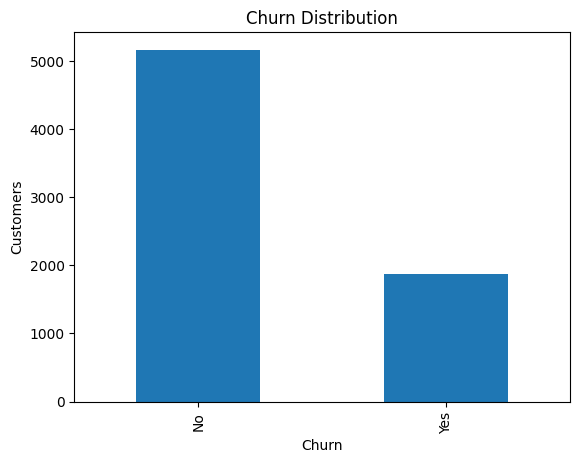

In [14]:
import matplotlib.pyplot as plt

df["Churn"].value_counts().plot(kind="bar")
plt.title("Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customers")
plt.show()

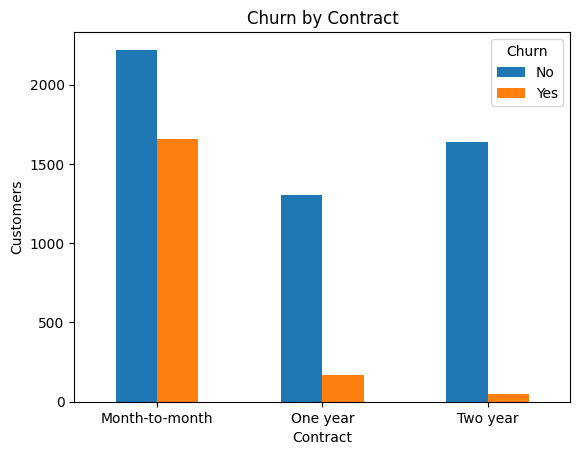

In [15]:
pd.crosstab(df["Contract"], df["Churn"]).plot(kind="bar")
plt.title("Churn by Contract")
plt.xlabel("Contract")
plt.ylabel("Customers")
plt.xticks(rotation=0)
plt.show()

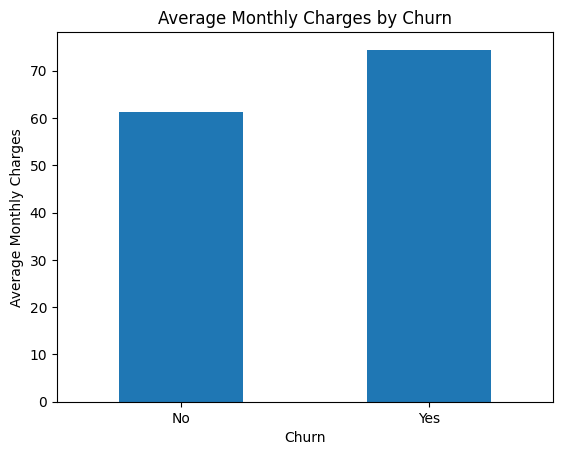

In [16]:
df.groupby("Churn")["MonthlyCharges"].mean().plot(kind="bar")
plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.show()

## 4. Feature Engineering and Encoding

In [17]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop("Churn", axis=1)
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7032, 30)
y shape: (7032,)


## 5. Training and Testing

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 30)
Testing data: (1407, 30)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

model1 = LogisticRegression(solver="liblinear")
model2 = DecisionTreeClassifier(random_state=42)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

## 6. Model Evaluation

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred1))
print("Precision:", precision_score(y_test, pred1))
print("Recall:", recall_score(y_test, pred1))
print("F1 Score:", f1_score(y_test, pred1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred1))

print("\nDecision Tree")
print("Accuracy:", accuracy_score(y_test, pred2))
print("Precision:", precision_score(y_test, pred2))
print("Recall:", recall_score(y_test, pred2))
print("F1 Score:", f1_score(y_test, pred2))
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred2))

if f1_score(y_test, pred1) > f1_score(y_test, pred2):
    print("\nFinal Model: Logistic Regression")
else:
    print("\nFinal Model: Decision Tree")

Logistic Regression
Accuracy: 0.7874911158493249
Precision: 0.6229508196721312
Recall: 0.5080213903743316
F1 Score: 0.5596465390279823
Confusion Matrix:
[[918 115]
 [184 190]]

Decision Tree
Accuracy: 0.7249466950959488
Precision: 0.4838709677419355
Recall: 0.5213903743315508
F1 Score: 0.5019305019305019
Confusion Matrix:
[[825 208]
 [179 195]]

Final Model: Logistic Regression


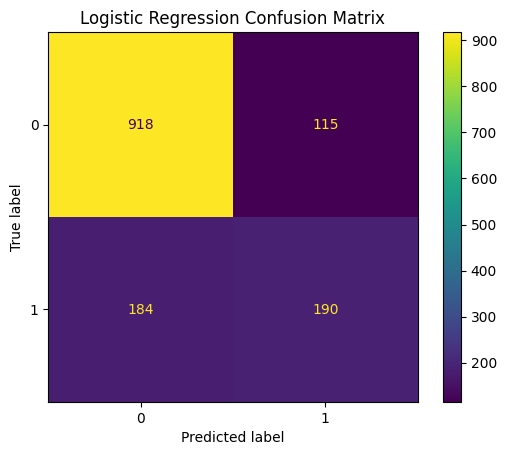

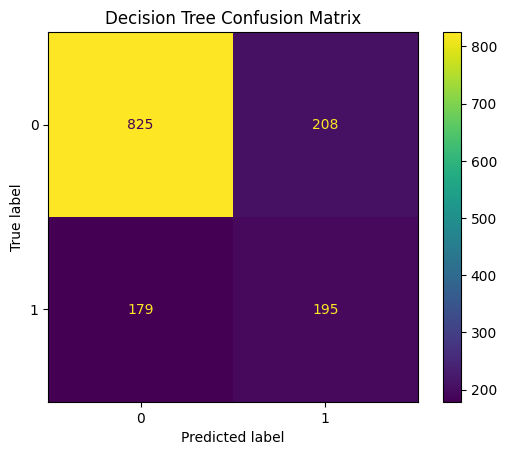

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred1)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, pred2)
plt.title("Decision Tree Confusion Matrix")
plt.show()

## 7. Prediction

In [22]:
sample = X_test.iloc[[0]]

if f1_score(y_test, pred1) > f1_score(y_test, pred2):
    final_model = model1
else:
    final_model = model2

prediction = final_model.predict(sample)[0]

if prediction == 1:
    print("Prediction: Churn")
else:
    print("Prediction: No Churn")

Prediction: No Churn
